In [1]:
import os
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.preprocessing import image_dataset_from_directory
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.applications.densenet import preprocess_input
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from sklearn.utils.class_weight import compute_class_weight

In [2]:
train_dir = r"D:\DR AND GLAUCOMA DETECTION PROJECT\datasets\Split_Dataset\train"
validation_dir = r"D:\DR AND GLAUCOMA DETECTION PROJECT\datasets\Split_Dataset\validation"
test_dir = r"D:\DR AND GLAUCOMA DETECTION PROJECT\datasets\Split_Dataset\test"

IMG_SIZE = (224, 224)
BATCH_SIZE = 8

In [3]:
train_dataset = image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True,
)

validation_dataset = image_dataset_from_directory(
    validation_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False,
)

test_dataset = image_dataset_from_directory(
    test_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False,
)

class_names = train_dataset.class_names
print(class_names)

Found 15442 files belonging to 3 classes.
Found 1930 files belonging to 3 classes.
Found 1932 files belonging to 3 classes.
['diabetic_retinopathy', 'glaucoma', 'normal']


In [4]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.map(
    lambda x, y: (preprocess_input(x), y),
    num_parallel_calls=AUTOTUNE
)

validation_dataset = validation_dataset.map(
    lambda x, y: (preprocess_input(x), y),
    num_parallel_calls=AUTOTUNE
)

test_dataset = test_dataset.map(
    lambda x, y: (preprocess_input(x), y),
    num_parallel_calls=AUTOTUNE
)

train_dataset = train_dataset.prefetch(AUTOTUNE)
validation_dataset = validation_dataset.prefetch(AUTOTUNE)
test_dataset = test_dataset.prefetch(AUTOTUNE)

In [5]:
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
])

In [6]:
labels = np.concatenate([y.numpy().argmax(axis=1) for x, y in train_dataset])

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(labels),
    y=labels
)

class_weights = dict(enumerate(class_weights))

print(class_weights)

{0: np.float64(0.6356301967564008), 1: np.float64(1.3499431768511234), 2: np.float64(1.4577551213065232)}


In [7]:
base_model = DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze the pretrained layers
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))

# Data augmentation
x = data_augmentation(inputs)

# DenseNet121 feature extraction
x = base_model(x, training=False)

# Classification head
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

outputs = layers.Dense(3, activation="softmax")(x)

model = models.Model(inputs, outputs)

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │         3,075 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,040,579 (26.86 MB)

 Trainable params: 3,075 (12.01 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [8]:
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [9]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

checkpoint = ModelCheckpoint(
    r"D:\DR AND GLAUCOMA DETECTION PROJECT\models\densenet121_best.keras",
    monitor="val_accuracy",
    save_best_only=True,
    verbose=1
)

In [10]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=10,
    class_weight=class_weights,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/10


d:\DR AND GLAUCOMA DETECTION PROJECT\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1931/1931 ━━━━━━━━━━━━━━━━━━━━ 0s 724ms/step - accuracy: 0.8373 - loss: 0.3498
Epoch 1: val_accuracy improved from None to 0.88601, saving model to D:\DR AND GLAUCOMA DETECTION PROJECT\models\densenet121_best.keras

Epoch 1: finished saving model to D:\DR AND GLAUCOMA DETECTION PROJECT\models\densenet121_best.keras
1931/1931 ━━━━━━━━━━━━━━━━━━━━ 1607s 819ms/step - accuracy: 0.8373 - loss: 0.3498 - val_accuracy: 0.8860 - val_loss: 0.2323
Epoch 2/10
1931/1931 ━━━━━━━━━━━━━━━━━━━━ 0s 721ms/step - accuracy: 0.8698 - loss: 0.2544
Epoch 2: val_accuracy did not improve from 0.88601
1931/1931 ━━━━━━━━━━━━━━━━━━━━ 1562s 809ms/step - accuracy: 0.8698 - loss: 0.2544 - val_accuracy: 0.8834 - val_loss: 0.2337
Epoch 3/10
1931/1931 ━━━━━━━━━━━━━━━━━━━━ 0s 709ms/step - accuracy: 0.8715 - loss: 0.2493
Epoch 3: val_accuracy did not improve from 0.88601
1931/1931 ━━━━━━━━━━━━━━━━━━━━ 1538s 796ms/step - accuracy: 0.8715 - loss: 0.2493 - val_accuracy: 0.8746 - val_loss: 0.2542
Epoch 4/10
1931/1931 ━━━━━━━━

In [11]:
test_loss, test_accuracy = model.evaluate(test_dataset)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

242/242 ━━━━━━━━━━━━━━━━━━━━ 243s 981ms/step - accuracy: 0.8934 - loss: 0.1956
Test Loss: 0.19556806981563568
Test Accuracy: 0.8933747410774231


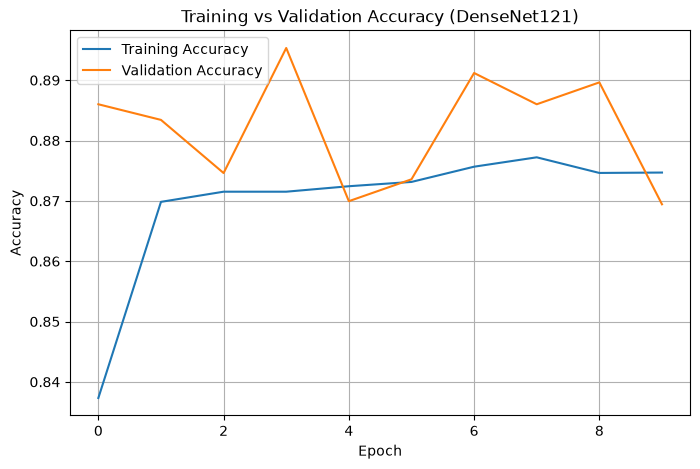

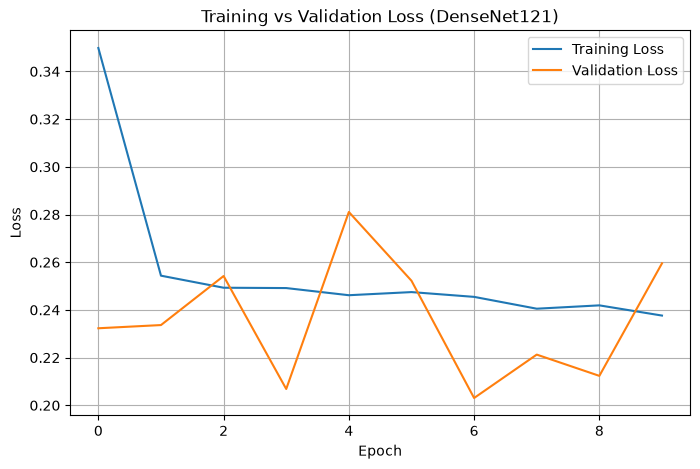

In [12]:
import matplotlib.pyplot as plt

# Accuracy
plt.figure(figsize=(8,5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training vs Validation Accuracy (DenseNet121)')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

# Loss
plt.figure(figsize=(8,5))
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training vs Validation Loss (DenseNet121)')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
plt.show()

                      precision    recall  f1-score   support

diabetic_retinopathy       0.89      0.91      0.90      1013
            glaucoma       1.00      1.00      1.00       477
              normal       0.78      0.75      0.76       442

            accuracy                           0.89      1932
           macro avg       0.89      0.88      0.89      1932
        weighted avg       0.89      0.89      0.89      1932

[[920   0  93]
 [  2 475   0]
 [111   0 331]]


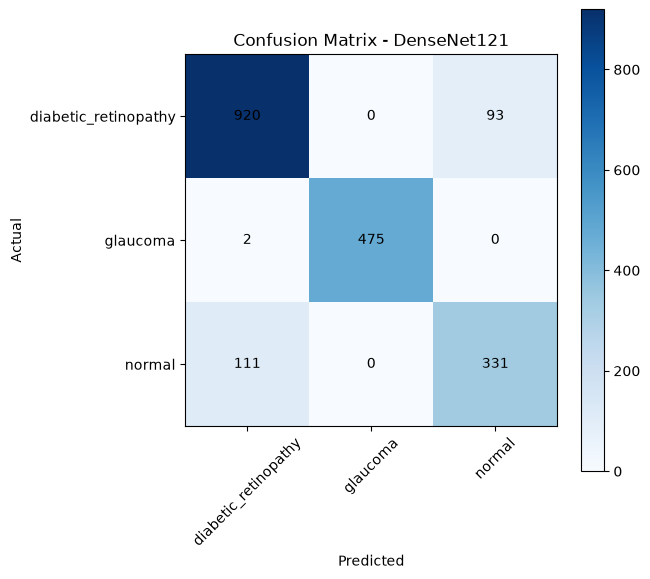

In [13]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

class_names = [
    "diabetic_retinopathy",
    "glaucoma",
    "normal"
]

true_labels = []
predicted_labels = []

for images, labels in test_dataset:
    predictions = model.predict(images, verbose=0)

    true_labels.extend(np.argmax(labels.numpy(), axis=1))
    predicted_labels.extend(np.argmax(predictions, axis=1))

print(classification_report(
    true_labels,
    predicted_labels,
    target_names=class_names
))

cm = confusion_matrix(true_labels, predicted_labels)

print(cm)

plt.figure(figsize=(6,6))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(3), class_names, rotation=45)
plt.yticks(range(3), class_names)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - DenseNet121")
plt.colorbar()

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.show()

In [14]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

accuracy = accuracy_score(true_labels, predicted_labels)
precision = precision_score(true_labels, predicted_labels, average='weighted')
recall = recall_score(true_labels, predicted_labels, average='weighted')
f1 = f1_score(true_labels, predicted_labels, average='weighted')

print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")

Accuracy : 0.8934
Precision: 0.8925
Recall   : 0.8934
F1-Score : 0.8928


In [15]:
model.save(r"D:\DR AND GLAUCOMA DETECTION PROJECT\models\densenet121_final.keras")

print("DenseNet121 model saved successfully!")

DenseNet121 model saved successfully!


In [16]:
print(history.history.keys())

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


In [17]:
print("Training Accuracy:", history.history['accuracy'])
print("Validation Accuracy:", history.history['val_accuracy'])

Training Accuracy: [0.8373267650604248, 0.8698354959487915, 0.8715192079544067, 0.8715192079544067, 0.8724258542060852, 0.8731381893157959, 0.8756637573242188, 0.8772179484367371, 0.8746276497840881, 0.8746923804283142]
Validation Accuracy: [0.8860103487968445, 0.8834196925163269, 0.8746113777160645, 0.8953368067741394, 0.8699482083320618, 0.8735751509666443, 0.8911917209625244, 0.8860103487968445, 0.889637291431427, 0.8694300651550293]


In [18]:
print("Best Training Accuracy:", history.history['accuracy'][6])
print("Best Validation Accuracy:", history.history['val_accuracy'][6])

Best Training Accuracy: 0.8756637573242188
Best Validation Accuracy: 0.8911917209625244
